# LAB | Central Limit Theorem and Normality Tests


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot

# Set random seed for reproducibility
np.random.seed(42)

# Setting plot style
plt.style.use('seaborn-v0_8')

## Challenge 1: Basic Central Limit Theorem Demonstration

In this challenge, you'll explore the fundamental concept of the Central Limit Theorem
by generating samples from different distributions and observing how their sample means
approach a normal distribution as sample size increases.

# Instructions
Instructions:
1. We'll create a non-normal distribution (exponential distribution)
2. Draw samples of different sizes and calculate their means
3. Observe how the distribution of sample means approaches normal distribution
4. Complete the code below to create histograms for sample means


In [2]:
# Set parameters
population_size = 10000
sample_sizes = [1, 5, 30, 100]  # Increasing sample sizes
n_samples = 1000  # Number of samples to draw for each sample size

# Create a non-normal population (exponential distribution with lambda=0.5)
population = np.random.exponential(scale=2, size=population_size)

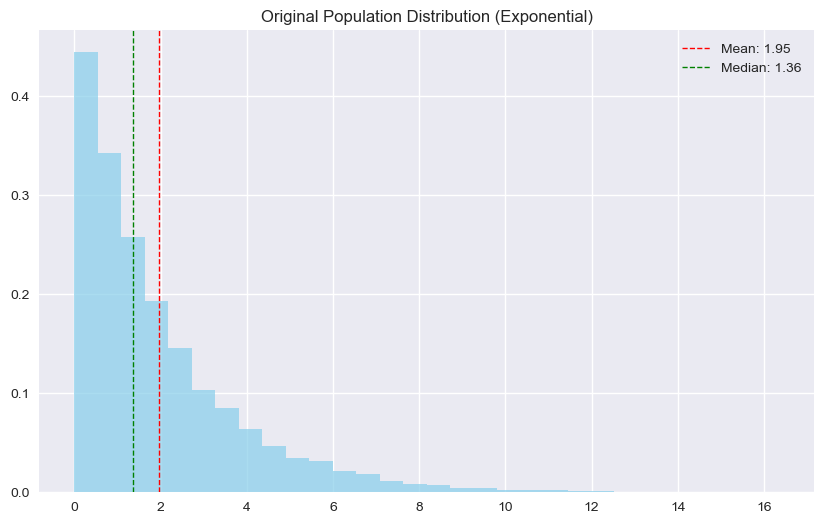

Population statistics:
Mean: 1.9550
Median: 1.3566
Variance: 3.7975
Skewness: 1.9190
Kurtosis: 5.1151



In [3]:
# Plot the original population distribution
plt.figure(figsize=(10, 6))
plt.hist(population, bins=30, alpha=0.7, color='skyblue', density=True)
plt.title('Original Population Distribution (Exponential)')
plt.axvline(np.mean(population), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(population):.2f}')
plt.axvline(np.median(population), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(population):.2f}')
plt.legend()
plt.show()

print(f"Population statistics:")
print(f"Mean: {np.mean(population):.4f}")
print(f"Median: {np.median(population):.4f}")
print(f"Variance: {np.var(population):.4f}")
print(f"Skewness: {stats.skew(population):.4f}")
print(f"Kurtosis: {stats.kurtosis(population):.4f}\n")

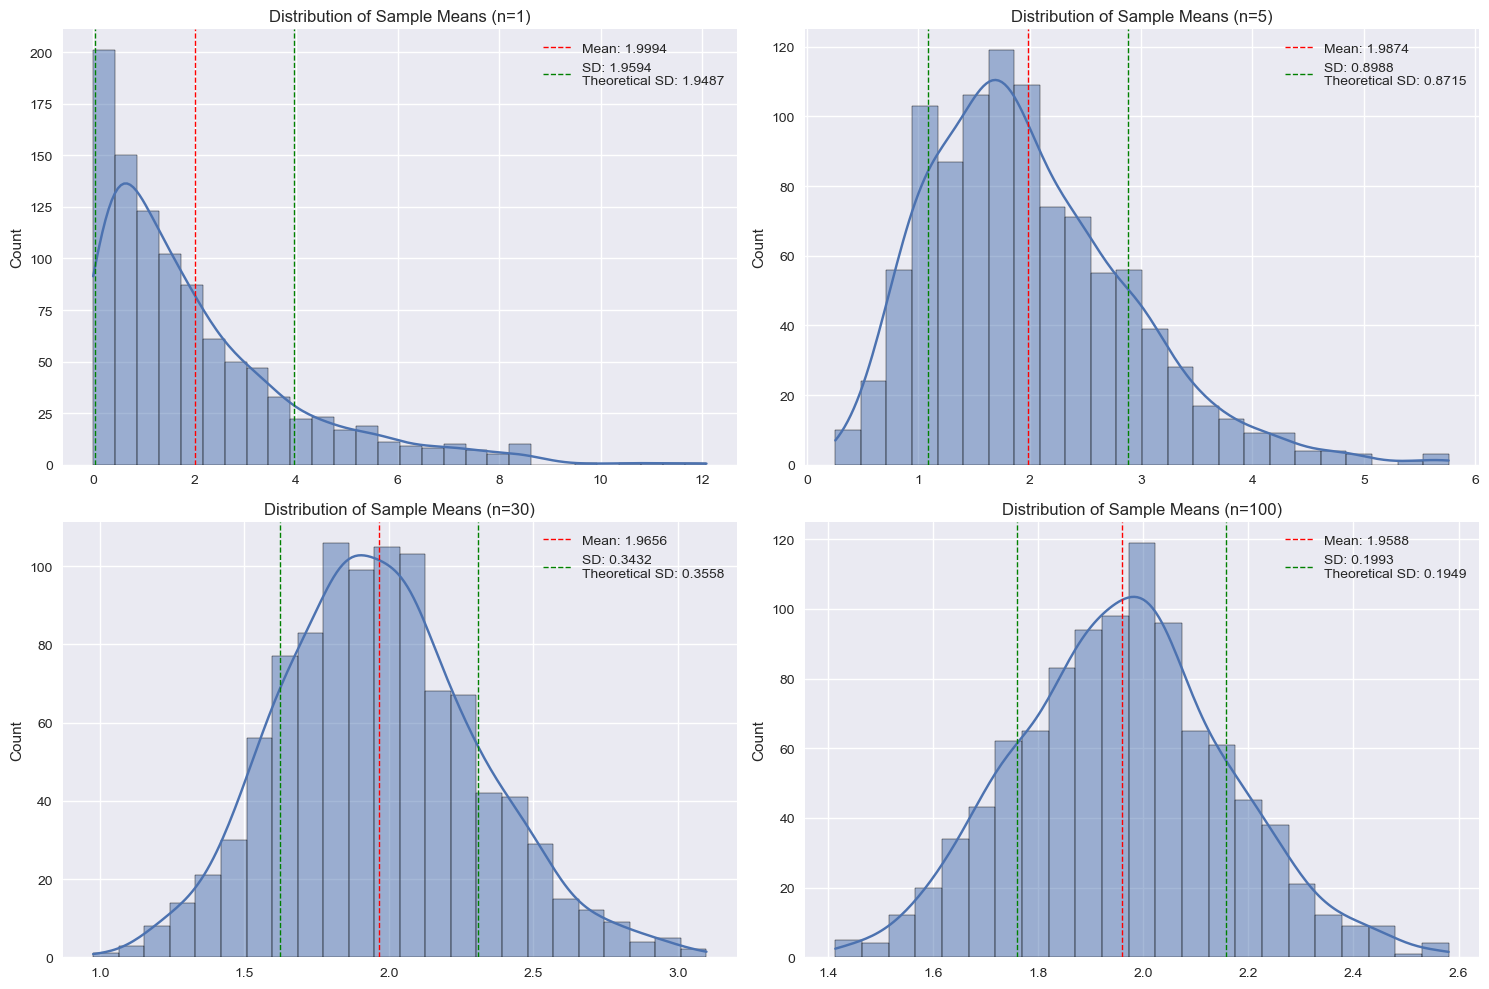

In [4]:
# Show how sample means approach normal distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, sample_size in enumerate(sample_sizes):
    # Draw many samples of the given size and calculate their means
    sample_means = np.array([np.mean(np.random.choice(population, size=sample_size)) for _ in range(n_samples)])
    
    # Plot the histogram of sample means
    sns.histplot(sample_means, kde=True, ax=axes[i])
    
    # Calculate statistics for the sample means
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means)
    
    # According to CLT, the standard deviation of sample means should be population_std / sqrt(sample_size)
    theoretical_std = np.std(population) / np.sqrt(sample_size)
    
    # Display the statistics
    axes[i].set_title(f'Distribution of Sample Means (n={sample_size})')
    axes[i].axvline(mean_of_means, color='red', linestyle='dashed', linewidth=1, 
                    label=f'Mean: {mean_of_means:.4f}')
    axes[i].axvline(mean_of_means + std_of_means, color='green', linestyle='dashed', linewidth=1,
                   label=f'SD: {std_of_means:.4f}\nTheoretical SD: {theoretical_std:.4f}')
    axes[i].axvline(mean_of_means - std_of_means, color='green', linestyle='dashed', linewidth=1)
    axes[i].legend()

plt.tight_layout()
plt.show()

Your Tasks:
1. Explain what happens to the distribution of sample means as sample size increases
2. Compare the observed standard deviation of sample means with the theoretical value
3. What is the theoretical SD formula according to the CLT?
4. How does the skewness of the distribution of sample means change with sample size?

In [5]:
# Answers to the tasks, backed by numbers
rows = []
for sample_size in sample_sizes:
    means = np.array([np.mean(np.random.choice(population, size=sample_size)) for _ in range(n_samples)])
    rows.append({
        "sample_size": sample_size,
        "observed_sd": means.std(),
        "theoretical_sd (sigma/sqrt(n))": population.std() / np.sqrt(sample_size),
        "skewness": stats.skew(means),
    })
display(pd.DataFrame(rows).round(4))

print("""
1. As the sample size grows, the distribution of sample means gets more symmetric and bell shaped,
   even though the population is strongly right-skewed (exponential).
2. The observed SD of the sample means matches sigma / sqrt(n) closely for every n.
3. Theoretical SD (standard error) = population SD / sqrt(sample size).
4. Skewness shrinks towards 0 as n grows (roughly 2 / sqrt(n) for an exponential population).
""")

,sample_size,observed_sd,theoretical_sd (sigma/sqrt(n)),skewness
0,1,2.1271,1.9487,1.9175
1,5,0.8703,0.8715,0.8820
2,30,0.3435,0.3558,0.3674
3,100,0.1909,0.1949,0.2075



1. As the sample size grows, the distribution of sample means gets more symmetric and bell shaped,
   even though the population is strongly right-skewed (exponential).
2. The observed SD of the sample means matches sigma / sqrt(n) closely for every n.
3. Theoretical SD (standard error) = population SD / sqrt(sample size).
4. Skewness shrinks towards 0 as n grows (roughly 2 / sqrt(n) for an exponential population).



## Challenge 2: CLT with Real-World Data


Now let's apply the Central Limit Theorem to a real-world dataset.
We'll use the famous Iris dataset.


In [6]:
# Load iris dataset
from sklearn.datasets import load_iris
iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

In [7]:
# Preview of the Iris dataset:
display(iris_df.head())
# Summary statistics:
print(iris_df.describe())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


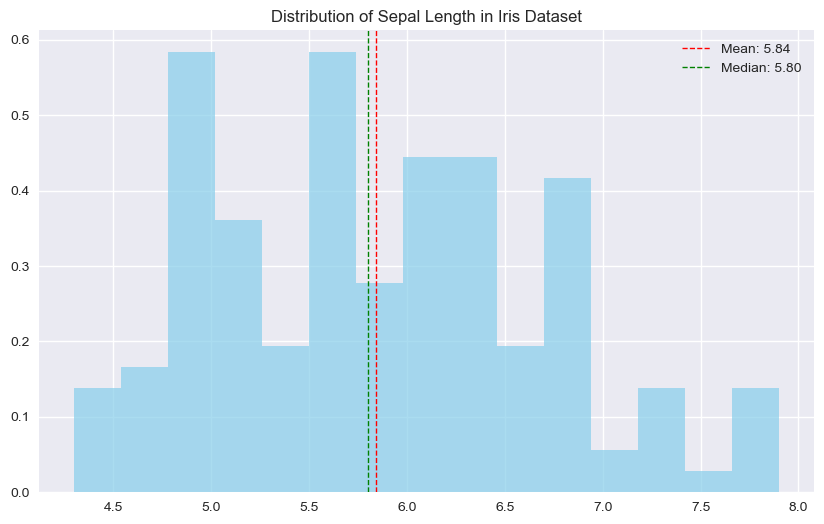

In [8]:
# Let's focus on sepal length for this exercise
sepal_length = iris_df['sepal length (cm)'].values

# Plot the original distribution
plt.figure(figsize=(10, 6))
plt.hist(sepal_length, bins=15, alpha=0.7, color='skyblue', density=True)
plt.title('Distribution of Sepal Length in Iris Dataset')
plt.axvline(np.mean(sepal_length), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(sepal_length):.2f}')
plt.axvline(np.median(sepal_length), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(sepal_length):.2f}')
plt.legend()
plt.show()

Your Tasks:
1. Complete the following code to draw samples of sepal length and compute their means
2. Create histograms for the distribution of sample means with sample sizes of 5, 15, and 30
3. Calculate and compare the standard deviation of the original data vs. the standard deviation of sample means
4. Test if the original data is normally distributed (using a method of your choice)

Original data: mean=5.843, sd=0.825
n= 5: SD of sample means=0.369 | sigma/sqrt(n)=0.369
n=15: SD of sample means=0.210 | sigma/sqrt(n)=0.213
n=30: SD of sample means=0.150 | sigma/sqrt(n)=0.151


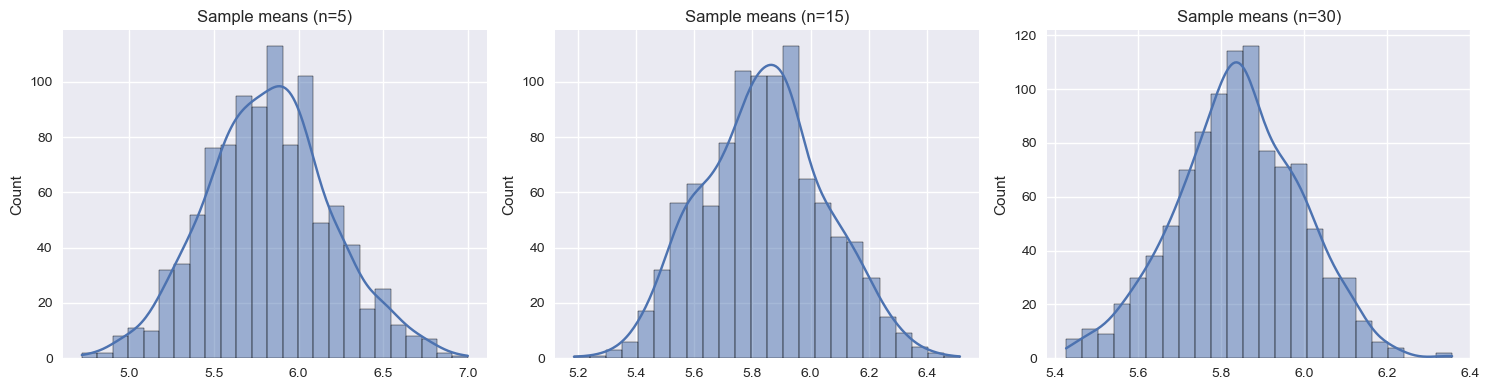

Shapiro-Wilk on sepal length: W=0.9761, p=0.0102
Conclusion: reject normality - the sample means are approximately normal anyway thanks to the CLT.


In [9]:
# Draw samples of the sepal length and look at the distribution of the sample means
sizes = [5, 15, 30]
n_draws = 1000
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print(f"Original data: mean={sepal_length.mean():.3f}, sd={sepal_length.std():.3f}")

for ax, size in zip(axes, sizes):
    means = np.array([np.random.choice(sepal_length, size=size).mean() for _ in range(n_draws)])
    sns.histplot(means, kde=True, ax=ax)
    ax.set_title(f"Sample means (n={size})")
    print(f"n={size:>2}: SD of sample means={means.std():.3f} | sigma/sqrt(n)={sepal_length.std() / np.sqrt(size):.3f}")
plt.tight_layout()
plt.show()

# Normality test of the original data (Shapiro-Wilk, H0: data is normal)
stat, p = stats.shapiro(sepal_length)
print(f"Shapiro-Wilk on sepal length: W={stat:.4f}, p={p:.4f}")
print("Conclusion:", "reject normality" if p < 0.05 else "no evidence against normality",
      "- the sample means are approximately normal anyway thanks to the CLT.")

## Challenge 3: CLT with Different Sample Statistics


The Central Limit Theorem applies not only to sample means but also to other
statistics like medians, variances, and proportions. Let's explore this concept.


In [10]:
# load_boston was removed from scikit-learn (>= 1.2), so we load the same data from OpenML
from sklearn.datasets import fetch_openml
boston_df = fetch_openml(name="boston", version=1, as_frame=True, parser="auto").frame.astype(float)

# Display of the Boston Housing dataset:
boston_df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [11]:
#Summary statistics for housing prices (MEDV):
boston_df['MEDV'].describe()

count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64

In [12]:
# Let's focus on housing prices (MEDV)
housing_prices = boston_df['MEDV'].values

# Create a binary variable: 1 if price > median, 0 otherwise
median_price = np.median(housing_prices)
housing_binary = (housing_prices > median_price).astype(int)

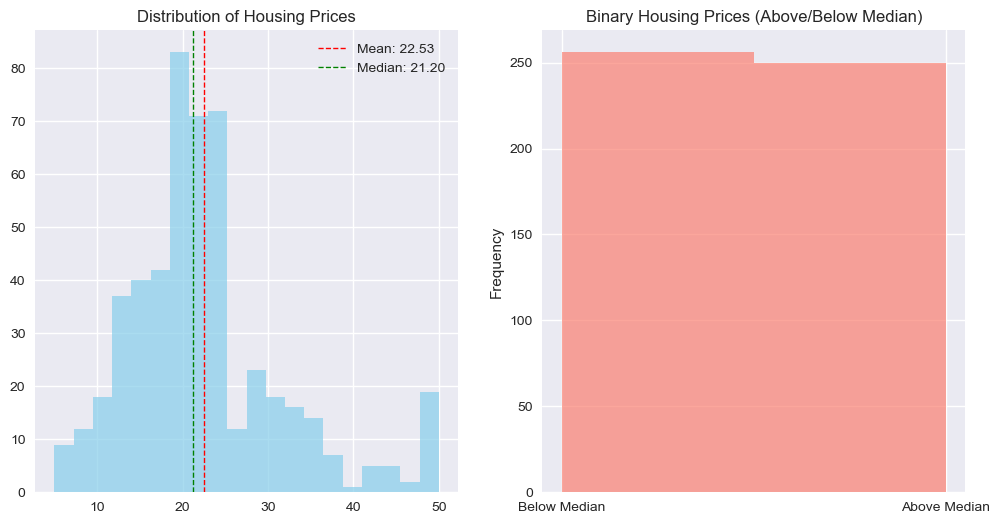

In [13]:
# Plot the original distribution
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(housing_prices, bins=20, alpha=0.7, color='skyblue')
plt.title('Distribution of Housing Prices')
plt.axvline(np.mean(housing_prices), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(housing_prices):.2f}')
plt.axvline(np.median(housing_prices), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(housing_prices):.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(housing_binary, bins=2, alpha=0.7, color='salmon')
plt.title('Binary Housing Prices (Above/Below Median)')
plt.xticks([0, 1], ['Below Median', 'Above Median'])
plt.ylabel('Frequency')
plt.show()

Your Tasks:
1. Implement sampling to examine the CLT's application to three different statistics:
   a) Sample means
   b) Sample medians
   c) Sample proportions (of houses above median price)
2. For each statistic, draw 1000 samples of size 30 and plot the distribution of the sample statistics
3. Compare the shapes of these three distributions
4. Discuss whether the CLT applies equally well to all three statistics.


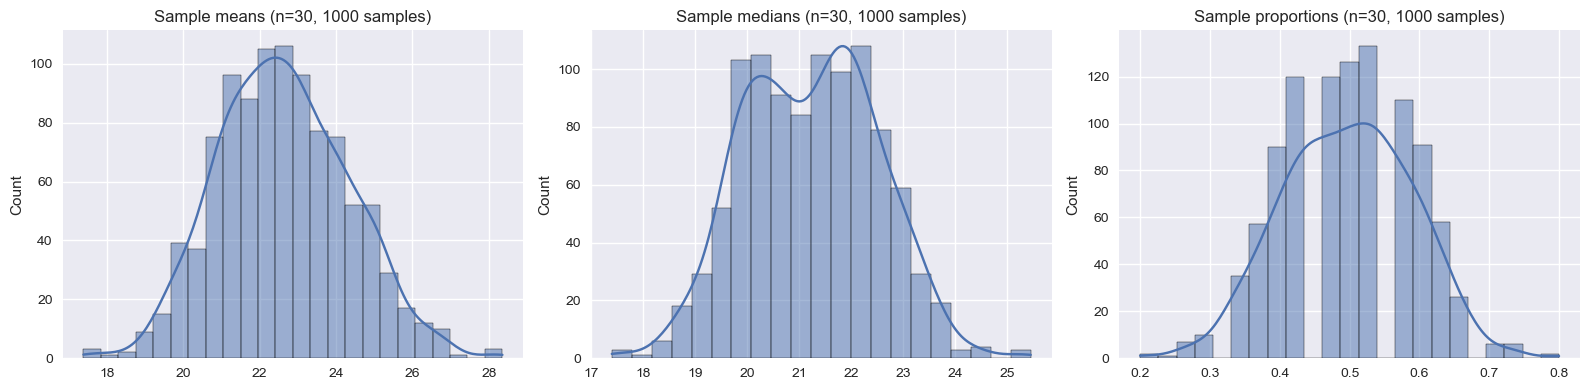

Skewness: {'mean': 0.172, 'median': 0.042, 'proportion': -0.04}

Comparison: the sample means are the most bell shaped. Medians converge more slowly and can look
lumpy/skewed because prices are skewed and capped at 50. Proportions are discrete (multiples of 1/30) but
look normal around 0.5 (binomial -> normal). The CLT holds for all three, but the speed of convergence
depends on the statistic and on the shape of the population.



In [14]:
# CLT for three different statistics: mean, median and proportion above the median price
n_draws, size = 1000, 30
means, medians, proportions = [], [], []
for _ in range(n_draws):
    idx = np.random.choice(len(housing_prices), size=size)
    means.append(housing_prices[idx].mean())
    medians.append(np.median(housing_prices[idx]))
    proportions.append(housing_binary[idx].mean())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, data, title in zip(axes, [means, medians, proportions],
                           ["Sample means", "Sample medians", "Sample proportions"]):
    sns.histplot(data, kde=True, ax=ax)
    ax.set_title(f"{title} (n={size}, {n_draws} samples)")
plt.tight_layout()
plt.show()

print("Skewness:", {n: round(float(stats.skew(d)), 3) for n, d in
                    zip(["mean", "median", "proportion"], [means, medians, proportions])})
print("""
Comparison: the sample means are the most bell shaped. Medians converge more slowly and can look
lumpy/skewed because prices are skewed and capped at 50. Proportions are discrete (multiples of 1/30) but
look normal around 0.5 (binomial -> normal). The CLT holds for all three, but the speed of convergence
depends on the statistic and on the shape of the population.
""")

## Challenge 4: Testing for Normality - Visual Methods

Before applying tests that assume normality, it's important to check if data
follows a normal distribution. Let's explore visual methods first.


In [15]:
# Load California Housing dataset
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing()
california_df = pd.DataFrame(data=california.data, columns=california.feature_names)
california_df['MedHouseVal'] = california.target

print("Preview of the California Housing dataset:")
display(california_df.head())

Preview of the California Housing dataset:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [16]:
print("\nSummary statistics for median income:")
print(california_df['MedInc'].describe())


Summary statistics for median income:
count    20640.000000
mean         3.870671
std          1.899822
min          0.499900
25%          2.563400
50%          3.534800
75%          4.743250
max         15.000100
Name: MedInc, dtype: float64


In [17]:
# We'll focus on median income for this challenge
median_income = california_df['MedInc'].values


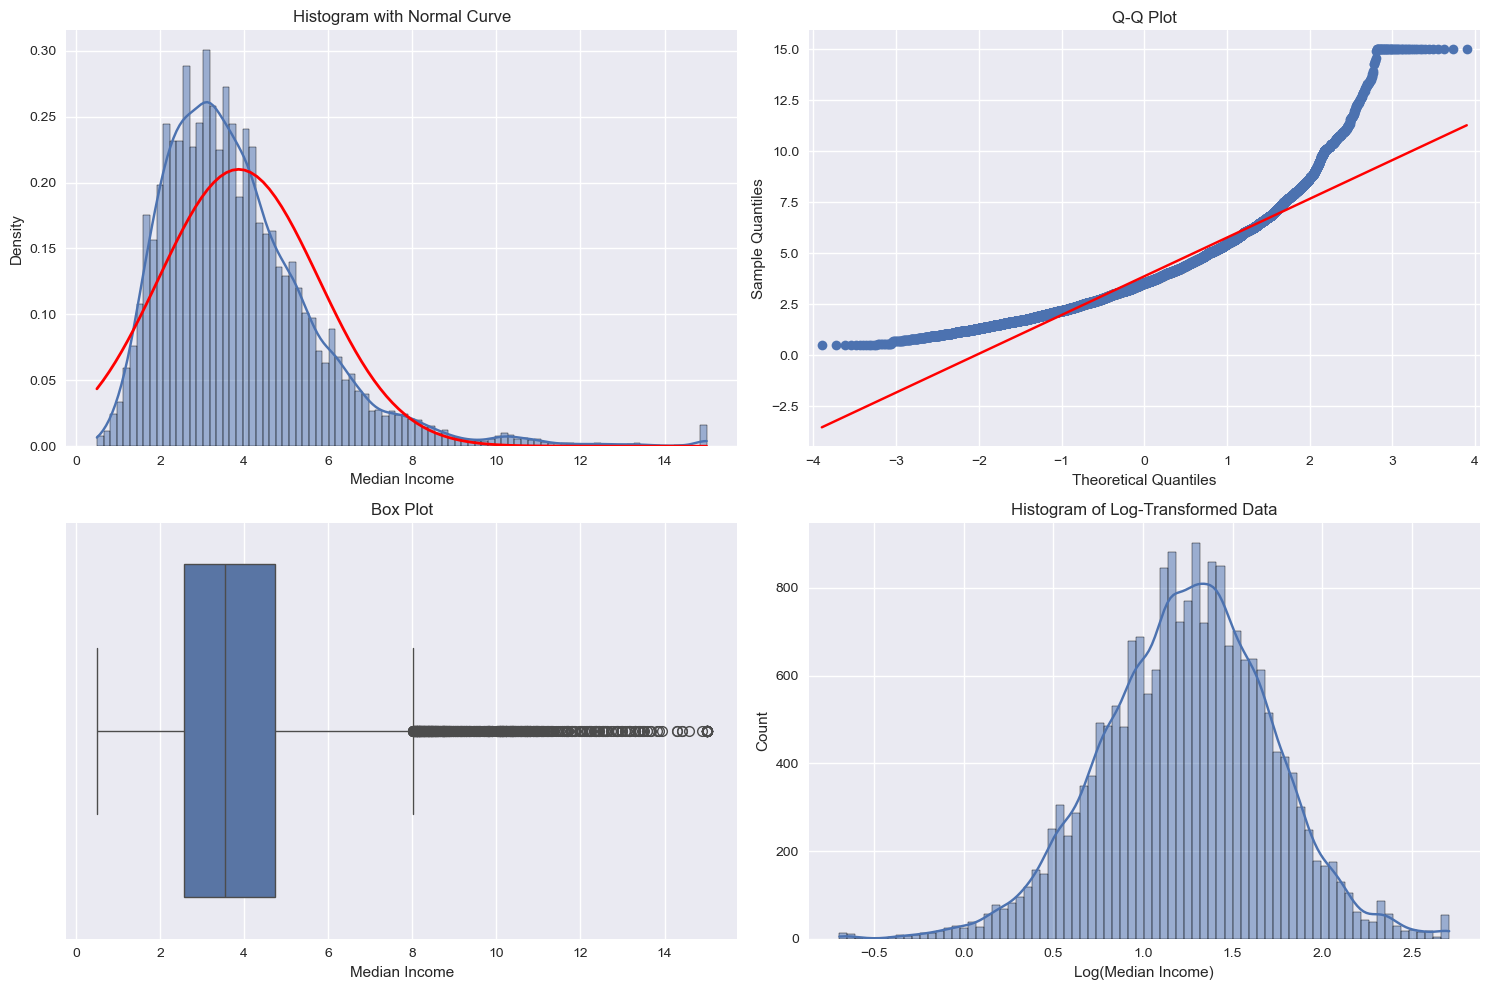

In [18]:
# Create some visualizations for normality assessment
plt.figure(figsize=(15, 10))

# Histogram with normal curve overlay
plt.subplot(2, 2, 1)
sns.histplot(median_income, kde=True, stat="density")
# Add theoretical normal curve
x = np.linspace(min(median_income), max(median_income), 100)
y = stats.norm.pdf(x, np.mean(median_income), np.std(median_income))
plt.plot(x, y, 'r-', linewidth=2)
plt.title('Histogram with Normal Curve')
plt.xlabel('Median Income')

# Q-Q plot
plt.subplot(2, 2, 2)
qqplot(median_income, line='s', ax=plt.gca())
plt.title('Q-Q Plot')

# Box plot
plt.subplot(2, 2, 3)
sns.boxplot(x=median_income)
plt.title('Box Plot')
plt.xlabel('Median Income')

# Log-transformed histogram
plt.subplot(2, 2, 4)
sns.histplot(np.log(median_income), kde=True)
plt.title('Histogram of Log-Transformed Data')
plt.xlabel('Log(Median Income)')

plt.tight_layout()
plt.show()

Your Tasks:
1. Interpret the four plots above. What do they tell you about the normality of the data?
2. Create at least two additional visualizations to assess normality
3. Discuss whether a transformation might help make the data more normal
4. Apply your chosen transformation and re-assess normality
5. When would it be important to have normally distributed data in statistical analysis?

After using Visualizations to assess normality:

6.  Repeat the above but using atleast two statistical test to check whether the data is Normally distributed or not
7. Make sure you apply the statistical test on both the original and transformed data.

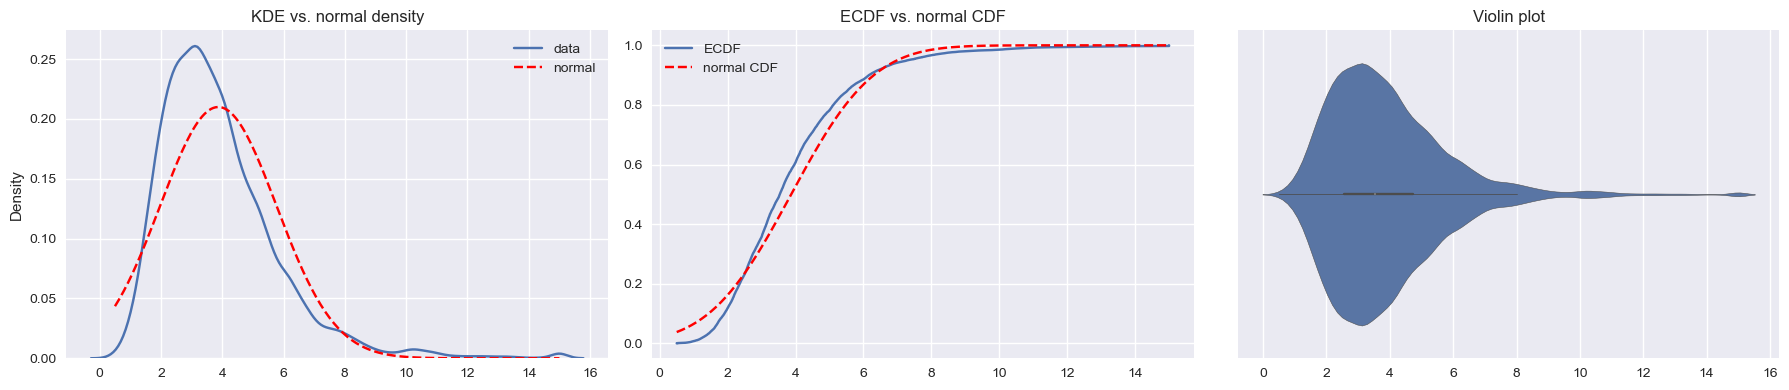

Skewness original=1.647 | log=-0.146 | sqrt=0.689 | box-cox (lambda=0.09)=0.005


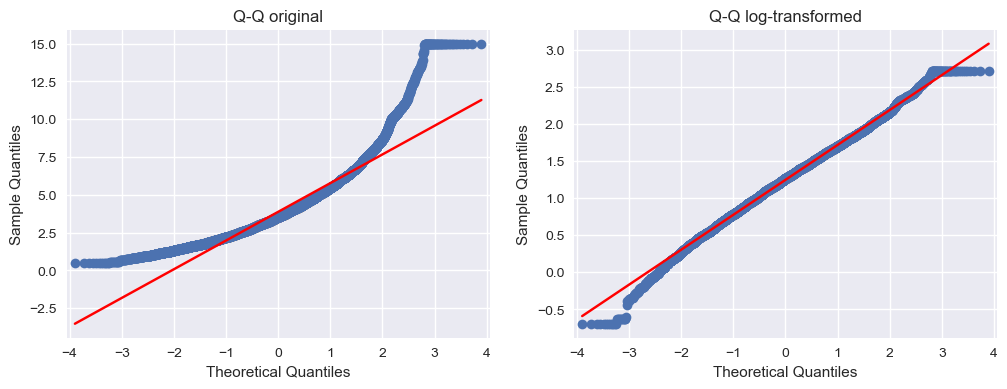

        original: Shapiro W=0.8969 (p=1.00e-49) | D'Agostino K2=1708.8 (p=0.00e+00) | Anderson A2=88.3 (5% critical value=0.786)
 log-transformed: Shapiro W=0.9962 (p=5.09e-10) | D'Agostino K2=55.2 (p=1.02e-12) | Anderson A2=3.3 (5% critical value=0.786)

Interpretation
1. The histogram is clearly right-skewed, the Q-Q plot bends away from the line in the upper tail and the boxplot
   shows many high outliers -> median income is NOT normally distributed.
2. Additional plots (KDE, ECDF) confirm the skew.
3. A log (or Box-Cox) transformation compresses the long right tail and reduces the skewness a lot.
4. After the transformation the Q-Q plot is much closer to the line, but the formal tests still reject exact
   normality with large samples (they detect even tiny deviations). "Close to normal" is what matters in practice.
5. Normality matters for t-tests, ANOVA, linear regression residuals, confidence intervals on small samples
   and any method that assumes Gaussian errors. With large 

In [19]:
# --- Additional visualisations: KDE vs. normal, and ECDF vs. normal CDF ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.kdeplot(median_income, ax=axes[0], label="data")
xs = np.linspace(median_income.min(), median_income.max(), 200)
axes[0].plot(xs, stats.norm.pdf(xs, median_income.mean(), median_income.std()), "r--", label="normal")
axes[0].set_title("KDE vs. normal density"); axes[0].legend()

sorted_inc = np.sort(median_income)
axes[1].plot(sorted_inc, np.arange(1, len(sorted_inc) + 1) / len(sorted_inc), label="ECDF")
axes[1].plot(xs, stats.norm.cdf(xs, median_income.mean(), median_income.std()), "r--", label="normal CDF")
axes[1].set_title("ECDF vs. normal CDF"); axes[1].legend()

sns.violinplot(x=median_income, ax=axes[2]); axes[2].set_title("Violin plot")
plt.tight_layout(); plt.show()

# --- Transformations ---
log_income = np.log(median_income)
sqrt_income = np.sqrt(median_income)
boxcox_income, lam = stats.boxcox(median_income)
print(f"Skewness original={stats.skew(median_income):.3f} | log={stats.skew(log_income):.3f} | "
      f"sqrt={stats.skew(sqrt_income):.3f} | box-cox (lambda={lam:.2f})={stats.skew(boxcox_income):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
qqplot(median_income, line="s", ax=axes[0]); axes[0].set_title("Q-Q original")
qqplot(log_income, line="s", ax=axes[1]); axes[1].set_title("Q-Q log-transformed")
plt.show()

# --- Statistical tests on original AND transformed data ---
# Shapiro-Wilk is unreliable for N > 5000, so we use a random subsample of 5000
sample = np.random.choice(median_income, min(5000, len(median_income)), replace=False)
log_sample = np.log(sample)
for name, data in [("original", sample), ("log-transformed", log_sample)]:
    w, p_sw = stats.shapiro(data)
    k2, p_k2 = stats.normaltest(data)  # D'Agostino-Pearson
    ad = stats.anderson(data, dist="norm")
    print(f"{name:>16}: Shapiro W={w:.4f} (p={p_sw:.2e}) | D'Agostino K2={k2:.1f} (p={p_k2:.2e}) | "
          f"Anderson A2={ad.statistic:.1f} (5% critical value={ad.critical_values[2]:.3f})")

print("""
Interpretation
1. The histogram is clearly right-skewed, the Q-Q plot bends away from the line in the upper tail and the boxplot
   shows many high outliers -> median income is NOT normally distributed.
2. Additional plots (KDE, ECDF) confirm the skew.
3. A log (or Box-Cox) transformation compresses the long right tail and reduces the skewness a lot.
4. After the transformation the Q-Q plot is much closer to the line, but the formal tests still reject exact
   normality with large samples (they detect even tiny deviations). "Close to normal" is what matters in practice.
5. Normality matters for t-tests, ANOVA, linear regression residuals, confidence intervals on small samples
   and any method that assumes Gaussian errors. With large n the CLT makes many of them robust.
""")